
<a href="https://colab.research.google.com/github/CienciaDatosUdea/005_CCA_Estudiantes/blob/main/Laboratorios/10_Lab_langevineP.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Movimiento browniano

Una partícula inmersa en un líquido experimenta fricción y
fluctuaciones producidas por las colisiones moleculares.
Para una partícula libre, la ecuación de Langevin es

$$
m\frac{d^2x}{dt^2}
=
-\gamma\frac{dx}{dt}+\xi(t),
$$

donde $m$ es la masa, $\gamma$ es el coeficiente de fricción
y $\xi(t)$ es la fuerza fluctuante.

## Propiedades del ruido térmico

La fuerza fluctuante tiene media cero:

$$
\langle\xi(t)\rangle=0.
$$

Esto significa que las fluctuaciones no tienen una dirección
preferida en promedio.

Para un líquido en equilibrio térmico, la correlación es

$$
\langle\xi(t)\xi(t')\rangle
=
2\gamma k_BT\,\delta(t-t').
$$

La delta de Dirac es una distribución matemática, definida
por su acción dentro de una integral:

$$
\int_{-\infty}^{\infty}
\delta(t-t')f(t')\,dt'=f(t).
$$

La correlación del ruido blanco se concentra en tiempos
coincidentes y se anula para tiempos distintos. El ruido
blanco se interpreta mediante sus integrales temporales.

## Formulación mediante un proceso de Wiener

Definimos la velocidad:

$$
v=\frac{dx}{dt}.
$$

El sistema se escribe formalmente como

$$
\begin{aligned}
\frac{dx}{dt}&=v,\\
m\frac{dv}{dt}&=-\gamma v+\xi(t).
\end{aligned}
$$

Mediante un proceso de Wiener, su formulación precisa es

$$
\begin{aligned}
dx_t&=v_t\,dt,\\
m\,dv_t&=-\gamma v_t\,dt
+\sqrt{2\gamma k_BT}\,dW_t.
\end{aligned}
$$

Los incrementos de Wiener en intervalos disjuntos son
independientes y satisfacen

$$
\Delta W_n
=
W_{t_{n+1}}-W_{t_n}
\sim\mathcal{N}(0,\Delta t).
$$

Para generarlos numéricamente usamos

$$
\Delta W_n=\sqrt{\Delta t}\,Z_n,
\qquad
Z_n\sim\mathcal{N}(0,1),
$$

con un nuevo $Z_n$ independiente en cada paso.

## Régimen sobreamortiguado

En escalas temporales grandes frente a $m/\gamma$, podemos
despreciar la inercia:

$$
\gamma\frac{dx}{dt}=\xi(t).
$$

La ecuación estocástica se reduce a

$$
dx_t=\sqrt{2D}\,dW_t,
\qquad
D=\frac{k_BT}{\gamma}.
$$

Para una posición inicial fija $x_0$, la solución es

$$
x_t=x_0+\sqrt{2D}\,W_t,
\qquad W_0=0.
$$

La media permanece en la posición inicial y la varianza
aumenta linealmente:

$$
\mathbb{E}[x_t]=x_0,
\qquad
\operatorname{Var}(x_t)=2Dt.
$$

Entre dos tiempos, la actualización exacta de este modelo es

$$
x_{n+1}
=
x_n+\sqrt{2D\,\Delta t}\,Z_n,
\qquad
Z_n\sim\mathcal{N}(0,1).
$$

Esta expresión describe una partícula libre en el régimen
sobreamortiguado.

Al incorporar un resorte, añadimos una deriva restauradora:

$$
dx_t
=
-\frac{k}{\gamma}x_t\,dt
+
\sqrt{2D}\,dW_t.
$$

Su aproximación de Euler–Maruyama es

$$
x_{n+1}
=
x_n-\frac{k}{\gamma}x_n\Delta t
+\sqrt{2D\,\Delta t}\,Z_n.
$$

El resorte confina las posiciones y el ruido mantiene las
fluctuaciones. A tiempos largos, la distribución se aproxima
a una gaussiana con media cero y varianza $k_BT/k$.

# Movimiento Browniano

\begin{equation}
\frac{d^2x}{dt^2}=-\gamma \frac{dx}{dt} + \xi(t)
\end{equation}

$\eta(t)$ Fuerza aleatoria producida por las colisiones colisiones moleculares $\langle \eta(t)\rangle=0.$, en promedio las colisiones que se presentan dan cero.
Para un liquido en equilibrio térmico, la intensidad viene dada por:

$\langle\xi(t)\xi(t') \rangle = 2\gamma k_B T  \delta(t-t') $

Para $\delta(\Delta t) = 0$, si $t!=t'$,

Para $\delta(\Delta t) = \infty$, si $t = t'$,



\begin{equation}
\frac{dx}{dt}=v
\end{equation}


\begin{equation}
\frac{dv}{dt}=-\gamma  \frac{dx}{dt} + \xi(t)
\end{equation}

El sistema de ecuaciones, se transforma, en, empleando un proceo de Wigner:


\begin{equation}
\begin{aligned}
dx(t)&=v(t)\,dt,\\
m\,dv(t)&=-\gamma v(t)\,dt
+\sqrt{2\gamma k_BT}\,dW(t).
\end{aligned}
\end{equation}



Cuya solución es

\begin{equation}
x(t+\Delta t)
=
x(t)+\sqrt{2D\,\Delta t}\,Z,
\qquad Z\sim\mathcal N(0,1).
\end{equation}



In [1]:
import numpy as np
import matplotlib.pyplot as plt

 # Simulacion del movimiento browniano

 Realizar un codigo para simular el movimiento browniano sin fuerza externa y con fuerza externa de la forma f=-kx

In [2]:
def euler_maruyama(x0, deriva, D, dt, n_pasos, rng):
    """Integra dx = deriva(x) dt + sqrt(2D) dW. Devuelve x con forma (n_pasos + 1, *x0.shape)."""
    x = np.empty((n_pasos + 1, *np.shape(x0)))
    x[0] = x0
    for n in range(n_pasos):
        x[n + 1] = x[n] + deriva(x[n]) * dt + np.sqrt(2 * D * dt) * rng.standard_normal(np.shape(x0))
    return x


rng = np.random.default_rng(0)
D, dt, n_pasos, n_tray = 1.0, 0.01, 1000, 2000
t = np.arange(n_pasos + 1) * dt

### Sin fuerza externa

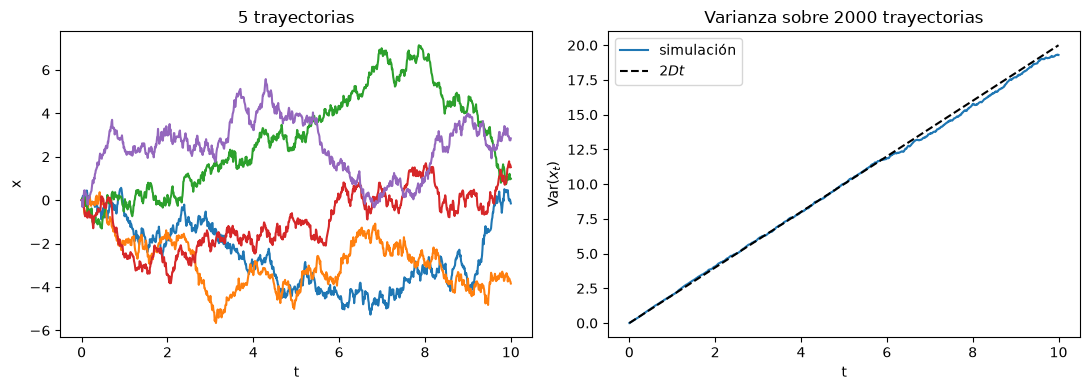

media en t = 10: 0.127 ± 0.098   (teoría: x0 = 0)


In [3]:
x_libre = euler_maruyama(np.zeros(n_tray), lambda x: 0, D, dt, n_pasos, rng)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(t, x_libre[:, :5])
axes[0].set(xlabel="t", ylabel="x", title="5 trayectorias")
axes[1].plot(t, x_libre.var(axis=1), label="simulación")
axes[1].plot(t, 2 * D * t, "k--", label="$2Dt$")
axes[1].set(xlabel="t", ylabel=r"Var$(x_t)$", title=f"Varianza sobre {n_tray} trayectorias")
axes[1].legend()
plt.tight_layout()
plt.show()

print(f"media en t = {t[-1]:.0f}: {x_libre[-1].mean():.3f} ± {x_libre[-1].std() / np.sqrt(n_tray):.3f}   (teoría: x0 = 0)")

La media se queda en $x_0$ y la varianza crece linealmente con el tiempo, como se espera de $\operatorname{Var}(x_t)=2Dt$.

### Con fuerza $f=-kx$

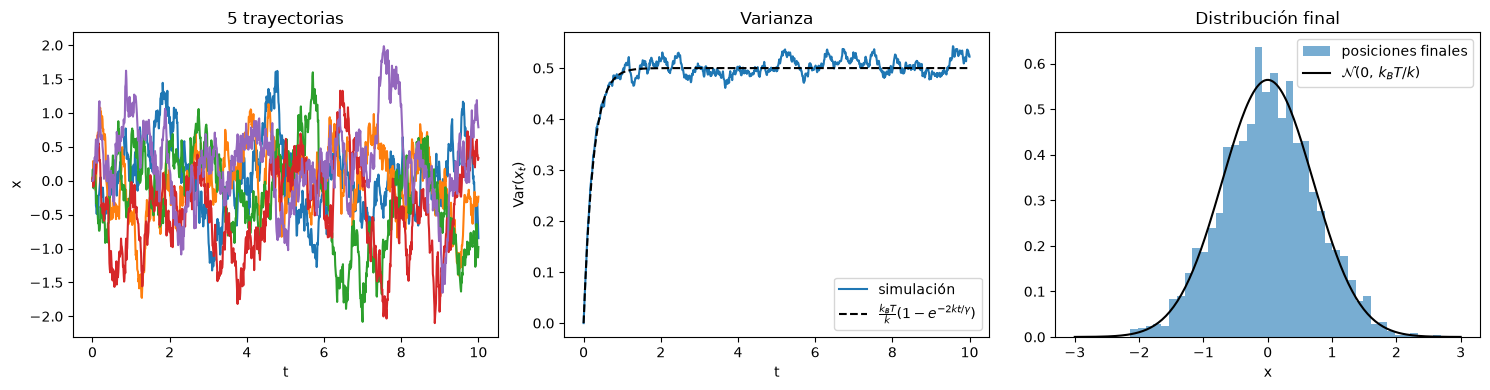

varianza final: 0.522 ± 0.017   (k_BT/k = 0.500)


In [4]:
k, gamma = 2.0, 1.0      # k_B T = D * gamma
var_eq = D * gamma / k   # k_B T / k

x_res = euler_maruyama(np.zeros(n_tray), lambda x: -k / gamma * x, D, dt, n_pasos, rng)

eje = np.linspace(-3, 3, 200)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].plot(t, x_res[:, :5])
axes[0].set(xlabel="t", ylabel="x", title="5 trayectorias")
axes[1].plot(t, x_res.var(axis=1), label="simulación")
axes[1].plot(t, var_eq * (1 - np.exp(-2 * k * t / gamma)), "k--", label=r"$\frac{k_BT}{k}(1-e^{-2kt/\gamma})$")
axes[1].set(xlabel="t", ylabel=r"Var$(x_t)$", title="Varianza")
axes[1].legend()
axes[2].hist(x_res[-1], bins=40, density=True, alpha=0.6, label="posiciones finales")
axes[2].plot(eje, np.exp(-eje**2 / (2 * var_eq)) / np.sqrt(2 * np.pi * var_eq), "k", label=r"$\mathcal{N}(0,\,k_BT/k)$")
axes[2].set(xlabel="x", title="Distribución final")
axes[2].legend()
plt.tight_layout()
plt.show()

print(f"varianza final: {x_res[-1].var():.3f} ± {x_res[-1].var() * np.sqrt(2 / n_tray):.3f}   (k_BT/k = {var_eq:.3f})")

Con el resorte la partícula queda confinada. La varianza deja de crecer y se satura en $k_BT/k$ después de un tiempo del orden de $\gamma/2k$, y la distribución final es la gaussiana de equilibrio.

# Con modelos tipo Score

# Dinámica de Langevin con un campo score

Para una densidad de probabilidad $p_\theta(\mathbf{x})$,
definimos el campo score como

$$
\mathbf{s}_\theta(\mathbf{x})
=
\nabla_{\mathbf{x}}\log p_\theta(\mathbf{x}).
$$

Este campo apunta hacia la dirección de máximo crecimiento
local del logaritmo de la densidad.

## Relación entre el score y la fuerza

Para una distribución de Boltzmann,

$$
p_\theta(\mathbf{x})
=
\frac{1}{Z_\theta}
\exp\left[-\frac{U_\theta(\mathbf{x})}{k_BT}\right],
$$

el score es

$$
\mathbf{s}_\theta(\mathbf{x})
=
-\frac{1}{k_BT}\nabla_{\mathbf{x}}U_\theta(\mathbf{x}).
$$

Como la fuerza es $\mathbf{F}_\theta=-\nabla U_\theta$,

$$
\mathbf{F}_\theta(\mathbf{x})
=
k_BT\,\mathbf{s}_\theta(\mathbf{x}).
$$

## Ecuación estocástica

La dinámica sobreamortiguada es

$$
d\mathbf{X}_t
=
\frac{\mathbf{F}_\theta(\mathbf{X}_t)}{\gamma}\,dt
+
\sqrt{2D}\,d\mathbf{W}_t,
\qquad
D=\frac{k_BT}{\gamma}.
$$

Sustituyendo la fuerza por su expresión en términos del score:

$$
d\mathbf{X}_t
=
D\,\mathbf{s}_\theta(\mathbf{X}_t)\,dt
+
\sqrt{2D}\,d\mathbf{W}_t.
$$

El campo produce un desplazamiento dirigido y el ruido
mantiene las fluctuaciones. Durante esta evolución,
$\theta$ permanece fijo.

## Incrementos de Wiener

En $d$ dimensiones,

$$
\Delta\mathbf{W}_n
=
\sqrt{\Delta t}\,\boldsymbol{\epsilon}_n,
\qquad
\boldsymbol{\epsilon}_n\sim\mathcal{N}(\mathbf{0},I_d),
$$

con nuevos vectores independientes en cada paso.

## Actualización numérica

La aproximación de Euler–Maruyama es

$$
\mathbf{X}_{n+1}
=
\mathbf{X}_n
+
D\,\mathbf{s}_\theta(\mathbf{X}_n)\Delta t
+
\sqrt{2D\Delta t}\,\boldsymbol{\epsilon}_n.
$$

En unidades donde $D=1$:

$$
\mathbf{X}_{n+1}
=
\mathbf{X}_n
+
\mathbf{s}_\theta(\mathbf{X}_n)\Delta t
+
\sqrt{2\Delta t}\,\boldsymbol{\epsilon}_n.
$$

Con el score exacto y condiciones adecuadas de convergencia,
la dinámica continua reproduce $p_\theta$ a tiempos largos.
La actualización numérica introduce un error de discretización.

## Ejemplo: distribución gaussiana

Para una gaussiana con media $\boldsymbol{\mu}$ y
covarianza $vI_d$,

$$
\mathbf{s}(\mathbf{x})
=
-\frac{\mathbf{x}-\boldsymbol{\mu}}{v}.
$$



In [5]:
import numpy as np
import matplotlib.pyplot as plt

# Gaussiana objetivo
mu = 0.0
varianza = 1.0

def densidad(x):
    return np.exp(-(x - mu)**2 / (2 * varianza)) / np.sqrt(
        2 * np.pi * varianza
    )

def score(x):
    return -(x - mu) / varianza



In [6]:
rng = np.random.default_rng(42)

n_trayectorias = 200
n_pasos = 1_000
dt = 0.01

# Todas las trayectorias comienzan en la misma posición
x = np.zeros((n_trayectorias, n_pasos))
np.shape(x)
t = np.arange(n_pasos+1 ) * dt

In [7]:
x = np.zeros((n_trayectorias, n_pasos + 1))

# Todas las trayectorias comienzan en cero
x[:, 0] = 0.0

for k in range(n_trayectorias):
    for j in range(n_pasos):
        ruido = rng.normal()

        x[k, j + 1] = (
            x[k, j]
            + dt * score(x[k, j])
            + np.sqrt(2 * dt) * ruido
        )

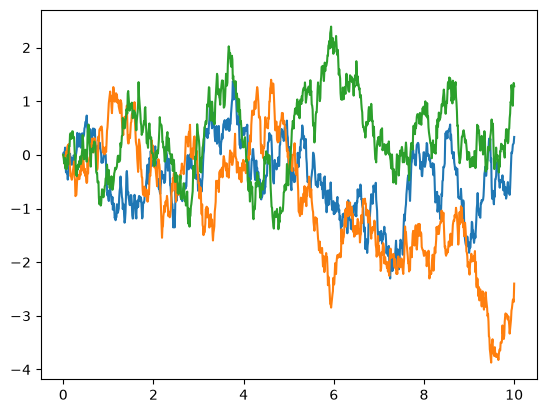

In [8]:
plt.plot(t, x[0])
plt.plot(t, x[1])
plt.plot(t, x[2])

In [9]:
# Se descarta el transitorio inicial (todas las trayectorias parten de x = 0)
x = x[:, 300:].ravel()

Media de las muestras:    0.0165
Varianza de las muestras: 1.0182
Varianza teórica discreta: 1.0050


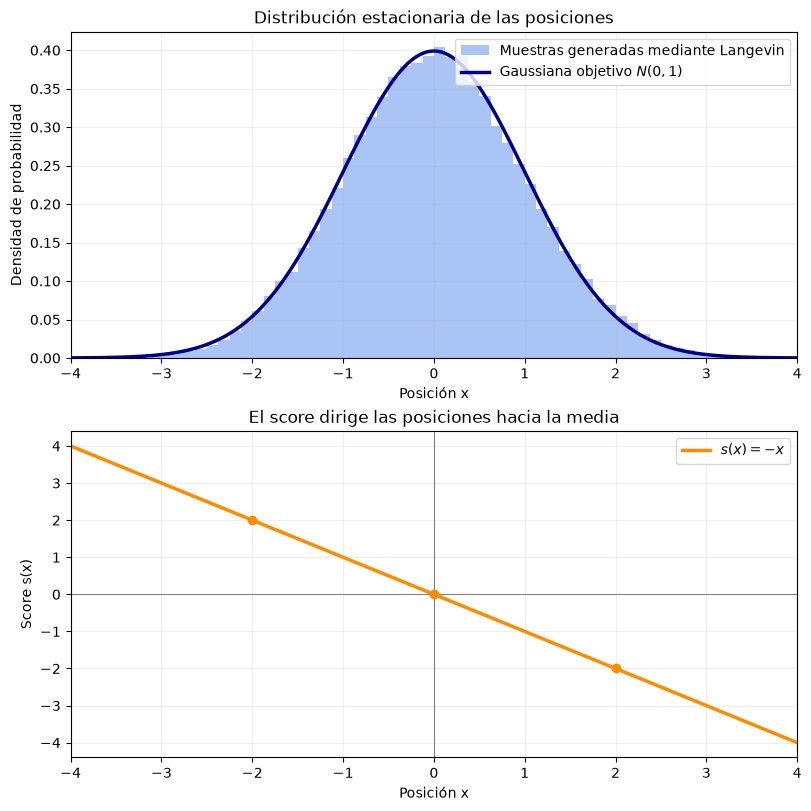

In [10]:
# Resultados
print(f"Media de las muestras:    {np.mean(x):.4f}")
print(f"Varianza de las muestras: {np.var(x):.4f}")

# Varianza estacionaria de la actualización discreta
varianza_discreta = varianza / (1 - dt / (2 * varianza))
print(f"Varianza teórica discreta: {varianza_discreta:.4f}")


# Gráficas
eje = np.linspace(-4, 4, 600)

fig, axes = plt.subplots(
    2, 1, figsize=(8, 8), constrained_layout=True
)

# Densidad objetivo e histograma de posiciones finales
axes[0].hist(
    x,
    bins=np.linspace(-4, 4, 65),
    density=True,
    color="cornflowerblue",
    alpha=0.55,
    label="Muestras generadas mediante Langevin"
)

axes[0].plot(
    eje,
    densidad(eje),
    color="navy",
    linewidth=2.5,
    label=r"Gaussiana objetivo ${N}(0,1)$"
)

axes[0].set(
    title="Distribución estacionaria de las posiciones",
    xlabel="Posición x",
    ylabel="Densidad de probabilidad",
    xlim=(-4, 4)
)
axes[0].legend()
axes[0].grid(alpha=0.2)

# Campo score
axes[1].plot(
    eje,
    score(eje),
    color="darkorange",
    linewidth=2.5,
    label=r"$s(x) = -x$"
)

axes[1].axhline(0, color="gray", linewidth=0.8)
axes[1].axvline(mu, color="gray", linewidth=0.8)

axes[1].scatter(
    [-2, 0, 2],
    score(np.array([-2, 0, 2])),
    color="darkorange",
    zorder=3
)

axes[1].set(
    title="El score dirige las posiciones hacia la media",
    xlabel="Posición x",
    ylabel="Score s(x)",
    xlim=(-4, 4)
)
axes[1].legend()
axes[1].grid(alpha=0.2)

plt.show()

Simule la dinámica de Langevin de partículas inicialmente distribuidas al azar en el plano, utilizando el campo score de una gaussiana de media \((0,0)\) y covarianza identidad. Visualice el campo y cinco trayectorias. Compare la distribución final de las partículas con la gaussiana objetivo y calcule su media y covarianza.

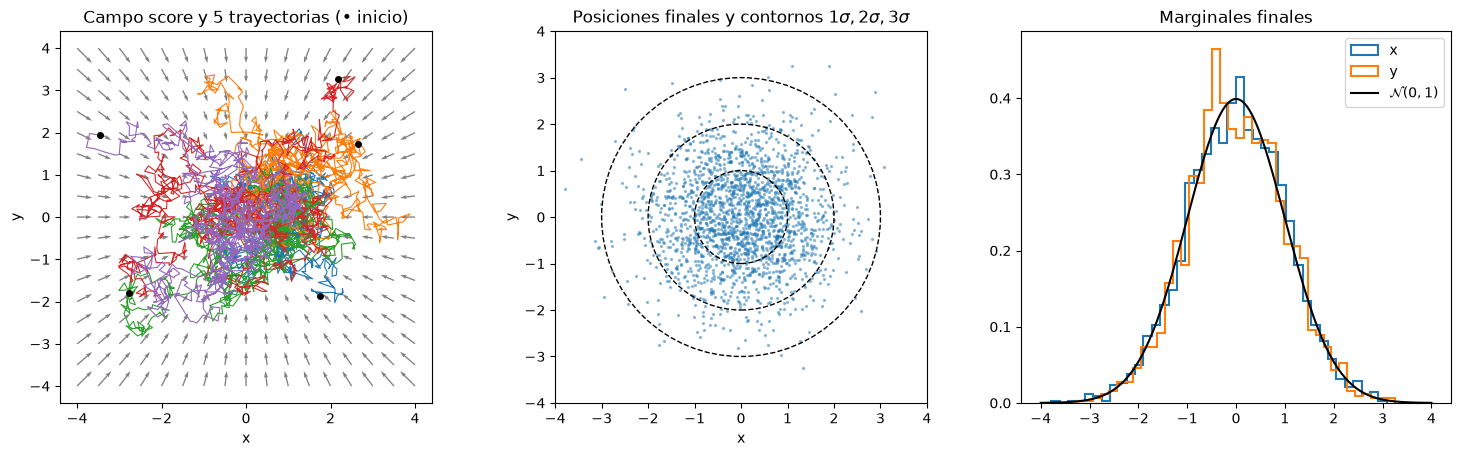

media: [0.014 0.012]   (objetivo: [0, 0])
covarianza:
 [[1.006 0.01 ]
 [0.01  0.973]]
varianza estacionaria de la discretización: 1.0050


In [11]:
# Gaussiana N(0, I) en 2D: `score` (mu = 0, varianza = 1) actúa componente a componente, s(x) = -x
n_part = 2000
x0 = rng.uniform(-4, 4, size=(n_part, 2))
X2 = euler_maruyama(x0, score, 1.0, dt, n_pasos, rng)  # D = 1
final = X2[-1]

g = np.linspace(-4, 4, 17)
GX, GY = np.meshgrid(g, g)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
axes[0].quiver(GX, GY, score(GX), score(GY), color="gray")
for j in range(5):
    axes[0].plot(X2[:, j, 0], X2[:, j, 1], lw=0.8)
    axes[0].plot(*X2[0, j], "ko", ms=4)
axes[0].set(xlabel="x", ylabel="y", title="Campo score y 5 trayectorias (• inicio)", aspect="equal")

axes[1].scatter(*final.T, s=2, alpha=0.4)
for r in (1, 2, 3):
    axes[1].add_patch(plt.Circle((0, 0), r, fill=False, ls="--", color="k"))
axes[1].set(xlabel="x", ylabel="y", title=r"Posiciones finales y contornos $1\sigma, 2\sigma, 3\sigma$",
            xlim=(-4, 4), ylim=(-4, 4), aspect="equal")

eje = np.linspace(-4, 4, 200)
for c, nombre in enumerate(["x", "y"]):
    axes[2].hist(final[:, c], bins=40, density=True, histtype="step", lw=1.5, label=nombre)
axes[2].plot(eje, densidad(eje), "k", label=r"$\mathcal{N}(0,1)$")
axes[2].set(title="Marginales finales")
axes[2].legend()
plt.tight_layout()
plt.show()

print("media:", final.mean(axis=0).round(3), "  (objetivo: [0, 0])")
print("covarianza:\n", np.cov(final.T).round(3))
print(f"varianza estacionaria de la discretización: {varianza / (1 - dt / (2 * varianza)):.4f}")

Las partículas arrancan distribuidas uniformemente en $[-4,4]^2$ y el score las va arrastrando hacia el origen. En $t=10$, que es mucho mayor que el tiempo de relajación ($\sim1$), la media es $\approx0$ y la covarianza $\approx I$, de modo que la distribución final reproduce la gaussiana objetivo. La discretización sube la varianza a $1/(1-\Delta t/2)\approx1.005$, pero esa diferencia es menor que el error estadístico con 2000 partículas.